# Leave-One-Chip-Out Cross-Validation
### Generalisierung auf unbekannte Kammer-/Kanal-Designs

**Ziel:** Fuer jeden Chip-Ordner wird geprueft, wie gut das Modell auf einem Design abschneidet, das es waehrend des Trainings dieses Folds nie gesehen hat.

**Setup:** `yolo26s-obb`, imgsz=640, 150 Epochen (Patience 30), Registrierungs-basierte Frame-Propagation (20 Frames/Position), zwei Klassen (`chamber_region`, `channel_region`) automatisch anhand des Box-Seitenverhaeltnisses klassifiziert.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

## Ergebnisse pro Chip-Ordner

In [2]:
results = pd.DataFrame([
    {"Ordner": "AMM01",                 "Klasse": "chamber_region", "mAP50": 0.995, "mAP50-95": 0.995, "Precision": 0.994, "Recall": 0.992, "Design im Training": "Ja (mehrfach)"},
    {"Ordner": "JK025",                  "Klasse": "chamber_region", "mAP50": 0.995, "mAP50-95": 0.995, "Precision": 0.990, "Recall": 0.989, "Design im Training": "Ja (mehrfach)"},
    {"Ordner": "Judith-Arg-20231126",    "Klasse": "channel_region", "mAP50": 0.916, "mAP50-95": 0.663, "Precision": 0.645, "Recall": 0.950, "Design im Training": "Ja (andere Session)"},
    {"Ordner": "Judith-Arg-20231127",    "Klasse": "channel_region", "mAP50": 0.974, "mAP50-95": 0.675, "Precision": 0.845, "Recall": 0.979, "Design im Training": "Ja (andere Session)"},
    {"Ordner": "Judith-Leu-20240308",    "Klasse": "channel_region", "mAP50": 0.538, "mAP50-95": 0.281, "Precision": 0.462, "Recall": 0.646, "Design im Training": "Teilweise"},
    {"Ordner": "Judith-Leu-20240927",    "Klasse": "beide (0/0)",    "mAP50": 0.000, "mAP50-95": 0.000, "Precision": 0.000, "Recall": 0.000, "Design im Training": "Nein"},
])

results.style.background_gradient(subset=["mAP50", "mAP50-95", "Precision", "Recall"], cmap="RdYlGn", vmin=0, vmax=1)

,Ordner,Klasse,mAP50,mAP50-95,Precision,Recall,Design im Training
0,AMM01,chamber_region,0.995000,0.995000,0.994000,0.992000,Ja (mehrfach)
1,JK025,chamber_region,0.995000,0.995000,0.990000,0.989000,Ja (mehrfach)
2,Judith-Arg-20231126,channel_region,0.916000,0.663000,0.645000,0.950000,Ja (andere Session)
3,Judith-Arg-20231127,channel_region,0.974000,0.675000,0.845000,0.979000,Ja (andere Session)
4,Judith-Leu-20240308,channel_region,0.538000,0.281000,0.462000,0.646000,Teilweise
5,Judith-Leu-20240927,beide (0/0),0.000000,0.000000,0.000000,0.000000,Nein


In [3]:
durchschnitt = results[["mAP50", "mAP50-95", "Precision", "Recall"]].mean()
print("Durchschnitt ueber alle Folds:")
print(durchschnitt.round(3))

Durchschnitt ueber alle Folds:
mAP50        0.736
mAP50-95     0.602
Precision    0.656
Recall       0.759
dtype: float64


## Zentraler Befund: Erkennung korreliert mit Design-Abdeckung im Training

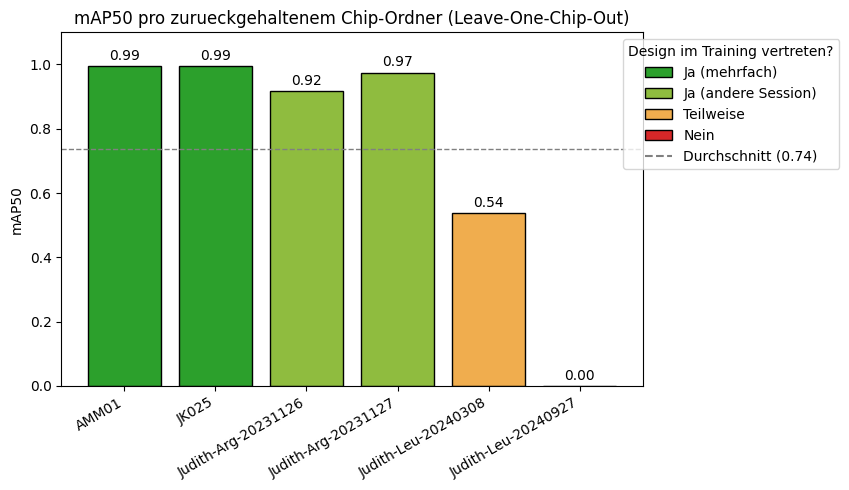

In [4]:
farben = {
    "Ja (mehrfach)": "#2ca02c",
    "Ja (andere Session)": "#8fbc3f",
    "Teilweise": "#f0ad4e",
    "Nein": "#d62728",
}
bar_farben = results["Design im Training"].map(farben)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(results["Ordner"], results["mAP50"], color=bar_farben, edgecolor="black")

ax.axhline(durchschnitt["mAP50"], color="gray", linestyle="--", linewidth=1, label=f"Durchschnitt ({durchschnitt['mAP50']:.2f})")

for bar, value in zip(bars, results["mAP50"]):
    ax.text(bar.get_x() + bar.get_width()/2, value + 0.02, f"{value:.2f}", ha="center", fontsize=10)

ax.set_ylabel("mAP50")
ax.set_ylim(0, 1.1)
ax.set_title("mAP50 pro zurueckgehaltenem Chip-Ordner (Leave-One-Chip-Out)")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

# Legende fuer die Farbcodierung
from matplotlib.patches import Patch
legend_elems = [Patch(facecolor=c, edgecolor="black", label=l) for l, c in farben.items()]
legend_elems.append(plt.Line2D([0], [0], color="gray", linestyle="--", label=f"Durchschnitt ({durchschnitt['mAP50']:.2f})"))
ax.legend(handles=legend_elems, title="Design im Training vertreten?", loc="upper right", bbox_to_anchor=(1.35, 1))

plt.tight_layout()
plt.show()

## Visueller Vergleich der Chip-Designs

Die mAP50-Werte werden nachvollziehbar, wenn man die tatsaechlichen Kammer-/Kanal-Strukturen sieht: `Judith-Leu-20240927` unterscheidet sich strukturell klar von allen anderen Designs im Datensatz.

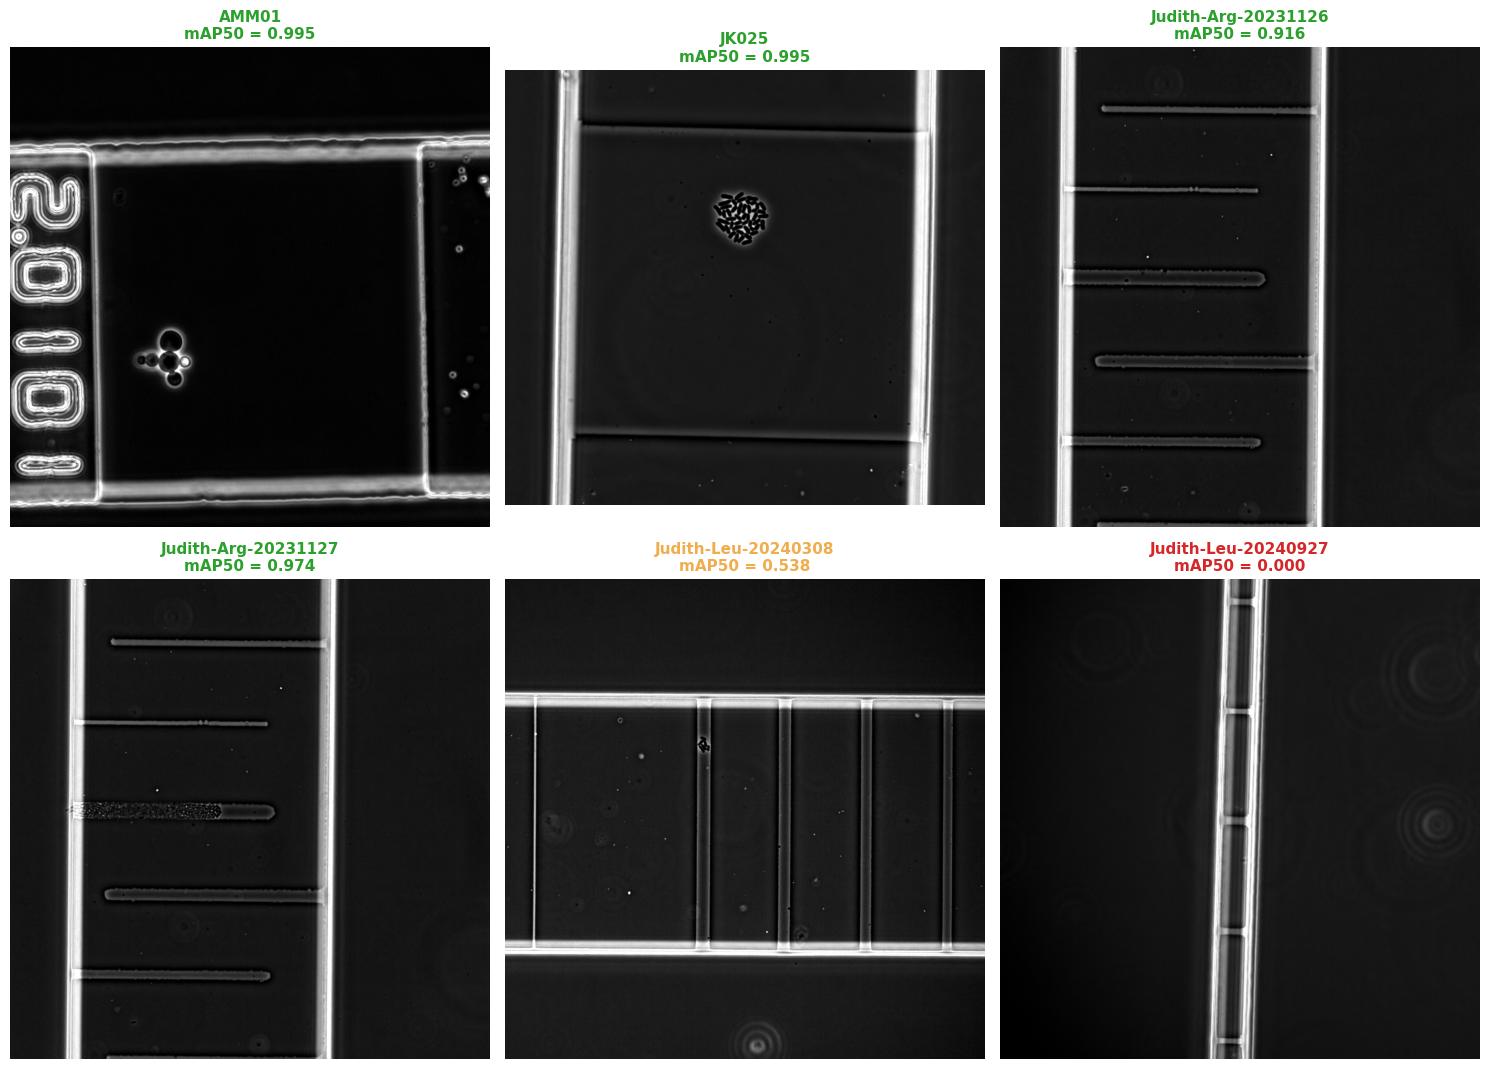

In [5]:
from PIL import Image

bilder_info = [
    ("AMM01", 0.995),
    ("JK025", 0.995),
    ("Judith-Arg-20231126", 0.916),
    ("Judith-Arg-20231127", 0.974),
    ("Judith-Leu-20240308", 0.538),
    ("Judith-Leu-20240927", 0.000),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 11))

for ax, (name, map50) in zip(axes.flat, bilder_info):
    img = Image.open(f"chip_images/{name}.png")
    ax.imshow(img, cmap="gray")
    farbe = "#d62728" if map50 == 0 else ("#2ca02c" if map50 > 0.9 else "#f0ad4e")
    ax.set_title(f"{name}\nmAP50 = {map50:.3f}", fontsize=11, color=farbe, fontweight="bold")
    ax.axis("off")

plt.tight_layout()
plt.show()

## Interpretation

- **`AMM01`, `JK025`** (Design mehrfach im Training vertreten) &rarr; nahezu perfekte Erkennung (mAP50 &asymp; 0.995)
- **`Judith-Arg-*`** (Kanal-Design an anderer Stelle im Training vertreten) &rarr; gute Erkennung (mAP50 0.92&ndash;0.97), aber schwaechere Box-Praezision (deutliche Luecke zwischen mAP50 und mAP50-95)
- **`Judith-Leu-20240308`** (Design nur teilweise/schwach vertreten) &rarr; deutlich schwaecher (mAP50 = 0.54)
- **`Judith-Leu-20240927`** (Design **komplett neu**, kein Gegenstueck im restlichen Datensatz) &rarr; **vollstaendiges Versagen** (mAP50 = 0.0)

**Schlussfolgerung:** Die Erkennungsleistung haengt unmittelbar davon ab, ob ein aehnliches Kammer-/Kanal-Design im Trainingsdatensatz vertreten ist &mdash; nicht von der reinen Datenmenge. Ein Design ohne jegliches Gegenstueck im Training wird zuverlaessig **nicht** erkannt, waehrend bereits eine einzelne verwandte Session (wie bei `Judith-Arg`) fuer brauchbare Ergebnisse ausreicht.

**Praktische Konsequenz:** Um diese Luecke zu schliessen, muesste mindestens eine annotierte Session des betroffenen Designs (`Judith-Leu-20240927`) ins Training aufgenommen werden &mdash; keine Kombination aus Hyperparametern, Augmentierung oder Modellgroesse kann das ersetzen.

# Inference Check auf zufälligem Datensatz

Hier ziehen wir aus dem MBVT-MP/Staff Ordner 4 ND2 Dateien mit Jeweils 3 Frames pro Position und insgesammt 5 Positionen raus. Diese guckt sich das fertig trainierte Model dann an.
Confidence Wert auf 0.25

## Lauf 1
- Bilder insgesamt: 57
- Bilder MIT mind. 1 Erkennung: 41 (71.9%)
- Bilder OHNE Erkennung: 16

- Erkennungen pro Bild: min=0  avg=0.89  max=5

- Erkennungen pro Klasse (mit durchschnittlicher Confidence):
  - chamber_region: 29 Erkennungen, Confidence min=0.47 avg=0.93 max=0.97
  - channel_region: 22 Erkennungen, Confidence min=0.25 avg=0.40 max=0.68



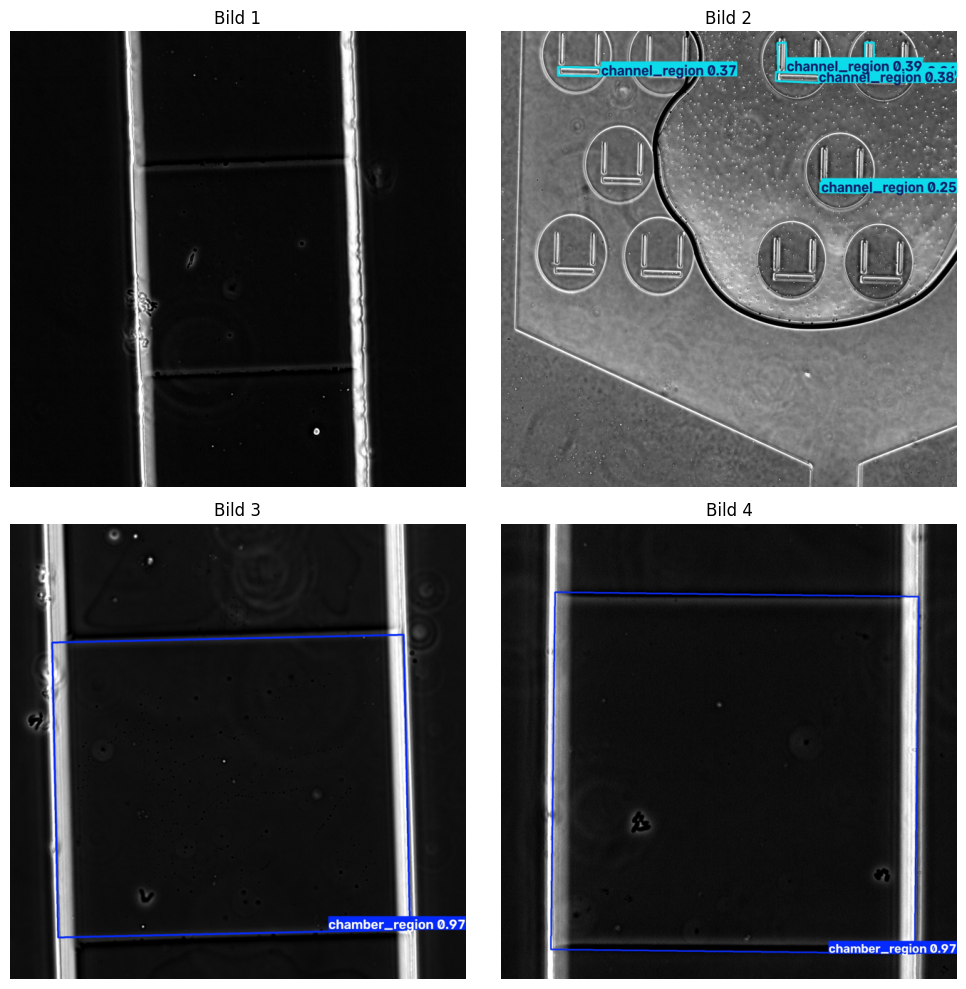

In [6]:
import matplotlib.pyplot as plt
from PIL import Image

img1 = Image.open("chip_images/Run 1/EH20_pos0_frame041.jpg")
img2 = Image.open("chip_images/Run 1/LoadingKeinPluronic_pos3_frame010.jpg")
img3 = Image.open("chip_images/Run 1/RH6_pos34_frame093.jpg")
img4 = Image.open("chip_images/Run 1/YS012_C.glut_WT_30sec_1min_2min_oszi_pos114_frame007.jpg")

img_resized1 = img1.resize((640, 640))
img_resized2 = img2.resize((640, 640))
img_resized3 = img3.resize((640, 640))
img_resized4 = img4.resize((640, 640))

bilder = [img_resized1, img_resized2, img_resized3, img_resized4]
titel = ["Bild 1", "Bild 2", "Bild 3", "Bild 4"]

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for ax, img, t in zip(axes.flat, bilder, titel):
    ax.imshow(img, cmap="gray")
    ax.set_title(t)
    ax.axis("off")

plt.tight_layout()
plt.show()

## Lauf 2

- Bilder insgesamt: 24 - Weniger Bilder da fehler beim verarbeiten mancher ND2 Dateien.
- Bilder MIT mind. 1 Erkennung: 8 (33.3%)
- Bilder OHNE Erkennung: 16

- Erkennungen pro Bild: min=0  avg=0.33  max=1

- Erkennungen pro Klasse (mit durchschnittlicher Confidence):
  - chamber_region: 8 Erkennungen, Confidence min=0.56 avg=0.83 max=0.93

Auffällig ist das eine eigentlich bekannte oder ähnliche ROI form, nicht erkannt wurde.

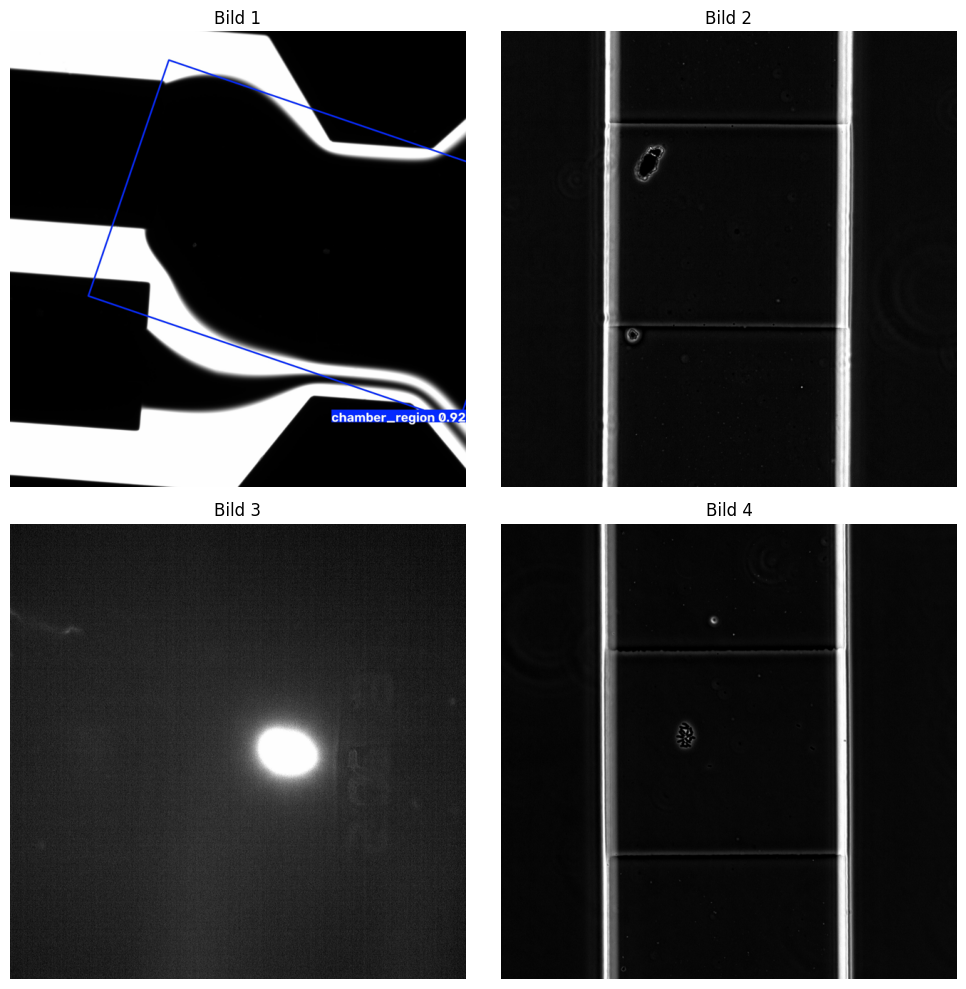

In [7]:
import matplotlib.pyplot as plt
from PIL import Image

img1 = Image.open("chip_images/Run 2/900nm_330nm_Inlet_2_3_Nodelay_130mbar_17,5_pos0_frame001.jpg")
img2 = Image.open("chip_images/Run 2/JK01_Fluorescin_30s_pos0_frame009.jpg")
img3 = Image.open("chip_images/Run 2/JW_nd61001_xy32_oszi_pos0_frame110.jpg")
img4 = Image.open("chip_images/Run 2/YS034_crop_chip2_pos3_frame054.jpg")

img_resized1 = img1.resize((640, 640))
img_resized2 = img2.resize((640, 640))
img_resized3 = img3.resize((640, 640))
img_resized4 = img4.resize((640, 640))

bilder = [img_resized1, img_resized2, img_resized3, img_resized4]
titel = ["Bild 1", "Bild 2", "Bild 3", "Bild 4"]

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for ax, img, t in zip(axes.flat, bilder, titel):
    ax.imshow(img, cmap="gray")
    ax.set_title(t)
    ax.axis("off")

plt.tight_layout()
plt.show()


## Lauf 3

- Bilder insgesamt: 60
- Bilder MIT mind. 1 Erkennung: 44 (73.3%)
- Bilder OHNE Erkennung: 16

- Erkennungen pro Bild: min=0  avg=0.87  max=2

- Erkennungen pro Klasse (mit durchschnittlicher Confidence):
  - chamber_region: 52 Erkennungen, Confidence min=0.31 avg=0.83 max=0.97

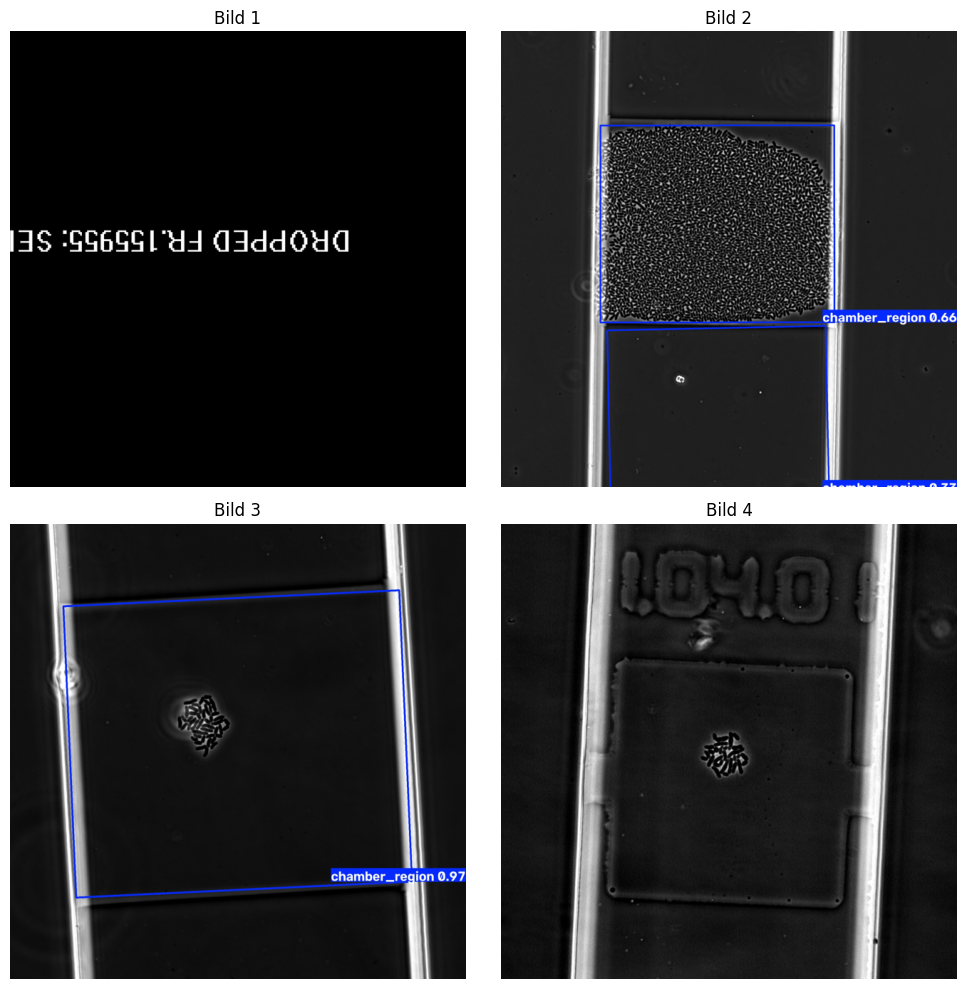

In [8]:
import matplotlib.pyplot as plt
from PIL import Image

img1 = Image.open("chip_images/Run 3/C.glut_LipB_30sec_1min_2min_pos0_frame027.jpg")
img2 = Image.open("chip_images/Run 3/JK006_pos0_frame087.jpg")
img3 = Image.open("chip_images/Run 3/RH19_crop_pos4_frame056.jpg")
img4 = Image.open("chip_images/Run 3/YS035_crop_chip1_pos3_frame120.jpg")

img_resized1 = img1.resize((640, 640))
img_resized2 = img2.resize((640, 640))
img_resized3 = img3.resize((640, 640))
img_resized4 = img4.resize((640, 640))

bilder = [img_resized1, img_resized2, img_resized3, img_resized4]
titel = ["Bild 1", "Bild 2", "Bild 3", "Bild 4"]

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for ax, img, t in zip(axes.flat, bilder, titel):
    ax.imshow(img, cmap="gray")
    ax.set_title(t)
    ax.axis("off")

plt.tight_layout()
plt.show()

## Lauf 4

- Skript angepasst


**Gesamtergebnis**

| Metrik | Wert |
|---|---|
| Bilder insgesamt | 46 |
| Bilder MIT mind. 1 Erkennung | 31 (67,4 %) |
| Bilder OHNE Erkennung | 15 |
| Erkennungen pro Bild (min / avg / max) | 0 / 0,74 / 2 |

**Erkennungen pro Klasse**

| Klasse | Erkennungen | Confidence min | Confidence avg | Confidence max |
|---|---|---|---|---|
| chamber_region | 30 | 0,85 | 0,92 | 0,97 |
| channel_region | 4 | 0,27 | 0,34 | 0,40 |

**Ergebnis pro Chip-Art**

| Chip-Art | Bilder | Erkannt | Rate | Klassen |
|---|---|---|---|---|
| `20260901_mik1` | 15 | 1 | 6,7 % | channel_region: 1 |
| `JW_nd59_crop` | 15 | 15 | 100,0 % | chamber_region: 15, channel_region: 3 |
| `JW_nd77_crop` | 15 | 15 | 100,0 % | chamber_region: 15 |
| `Z2_40x_180nm_10µm` | 1 | 0 | 0,0 % | – |

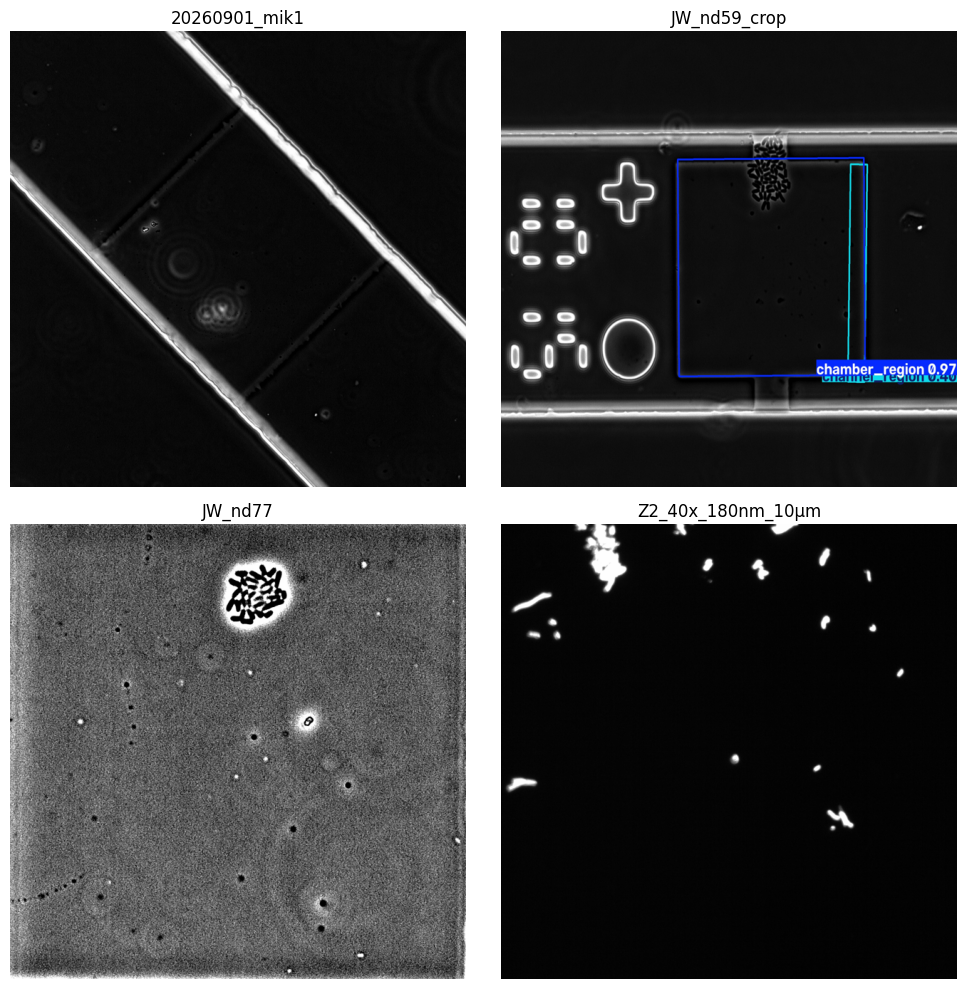

In [9]:
import matplotlib.pyplot as plt
from PIL import Image

img1 = Image.open("chip_images/Run 4/20260901_mik1_pos5_frame091.jpg")
img2 = Image.open("chip_images/Run 4/JW_nd59_crop_pos15_frame028.jpg")
img3 = Image.open("chip_images/Run 4/JW_nd77_crop_pos10_frame052.jpg")
img4 = Image.open("chip_images/Run 4/Z2_40x_180nm_10µm_pos0_frame000.jpg")

img_resized1 = img1.resize((640, 640))
img_resized2 = img2.resize((640, 640))
img_resized3 = img3.resize((640, 640))
img_resized4 = img4.resize((640, 640))

bilder = [img_resized1, img_resized2, img_resized3, img_resized4]
titel = ["20260901_mik1", "JW_nd59_crop", "JW_nd77", "Z2_40x_180nm_10µm"]

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for ax, img, t in zip(axes.flat, bilder, titel):
    ax.imshow(img, cmap="gray")
    ax.set_title(t)
    ax.axis("off")

plt.tight_layout()
plt.show()

## Lauf 5

**Gesamtergebnis**

| Metrik | Wert |
|---|---|
| Bilder insgesamt | 24 |
| Bilder MIT mind. 1 Erkennung | 19 (79,2 %) |
| Bilder OHNE Erkennung | 5 |
| Erkennungen pro Bild (min / avg / max) | 0 / 0,88 / 2 |

**Erkennungen pro Klasse**

| Klasse | Erkennungen | Confidence min | Confidence avg | Confidence max |
|---|---|---|---|---|
| chamber_region | 21 | 0,28 | 0,84 | 0,97 |
| channel_region | – | – | – | – |

> **Hinweis:** `channel_region` wurde auf keinem Bild erkannt.

**Ergebnis pro Chip-Art**

| Chip-Art | Bilder | Erkannt | Rate | Klassen |
|---|---|---|---|---|
| `1g4r_7a_40x_hotspot` | 3 | 2 | 66,7 % | chamber_region: 2 |
| `800nm_330nm_5Inlets_Nodelay_105mbar_23,75_minimum` | 3 | 2 | 66,7 % | chamber_region: 3 |
| `800nm_330nm_5Inlets_Nodelay_120mbar_20mbar_optimal` | 3 | 0 | 0,0 % | – |
| `YS301_crop_chip2` | 15 | 15 | 100,0 % | chamber_region: 16 |

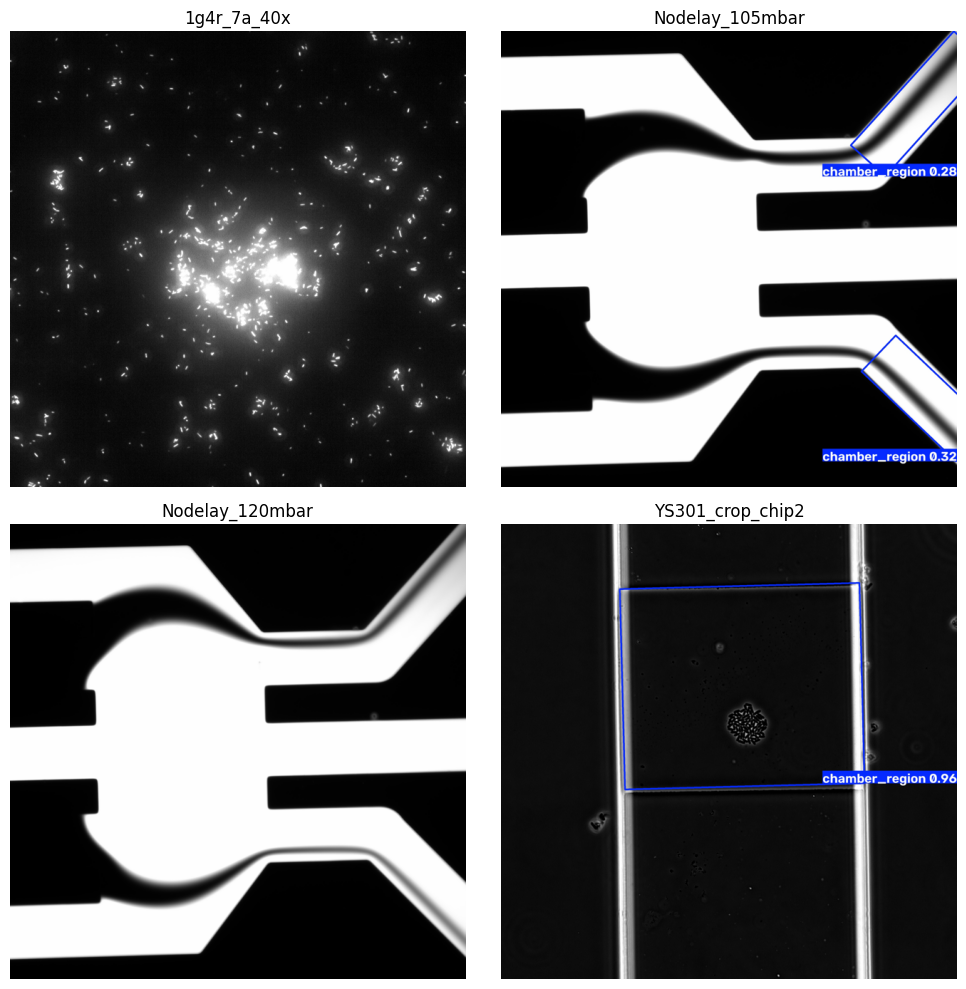

In [10]:
import matplotlib.pyplot as plt
from PIL import Image

img1 = Image.open("chip_images/Run 5/1g4r_7a_40x_hotspot_pos0_frame000.jpg")
img2 = Image.open("chip_images/Run 5/800nm_330nm_5Inlets_Nodelay_105mbar_23,75_minimum_pos0_frame053.jpg")
img3 = Image.open("chip_images/Run 5/800nm_330nm_5Inlets_Nodelay_120mbar_20mbar_optimal_pos0_frame069.jpg")
img4 = Image.open("chip_images/Run 5/YS301_crop_chip2_pos6_frame041.jpg")

img_resized1 = img1.resize((640, 640))
img_resized2 = img2.resize((640, 640))
img_resized3 = img3.resize((640, 640))
img_resized4 = img4.resize((640, 640))

bilder = [img_resized1, img_resized2, img_resized3, img_resized4]
titel = ["1g4r_7a_40x", "Nodelay_105mbar", "Nodelay_120mbar", "YS301_crop_chip2"]

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for ax, img, t in zip(axes.flat, bilder, titel):
    ax.imshow(img, cmap="gray")
    ax.set_title(t)
    ax.axis("off")

plt.tight_layout()
plt.show()

## Lauf 6

**Gesamtergebnis**

| Metrik | Wert |
|---|---|
| Bilder insgesamt | 48 |
| Bilder MIT mind. 1 Erkennung | 42 (87,5 %) |
| Bilder OHNE Erkennung | 6 |
| Erkennungen pro Bild (min / avg / max) | 0 / 2,31 / 7 |

**Erkennungen pro Klasse**

| Klasse | Erkennungen | Confidence min | Confidence avg | Confidence max |
|---|---|---|---|---|
| chamber_region | 57 | 0,28 | 0,71 | 0,97 |
| channel_region | 54 | 0,28 | 0,64 | 0,81 |

**Ergebnis pro Chip-Art**

| Chip-Art | Bilder | Erkannt | Rate | Klassen |
|---|---|---|---|---|
| `JK01_Fluorescin_30s` | 3 | 0 | 0,0 % | – |
| `JW_nd025_crop_1950µM` | 15 | 12 | 80,0 % | chamber_region: 12 |
| `JW_nd087_crop` | 15 | 15 | 100,0 % | chamber_region: 30, channel_region: 54 |
| `YS044_crop_chip1` | 15 | 15 | 100,0 % | chamber_region: 15 |

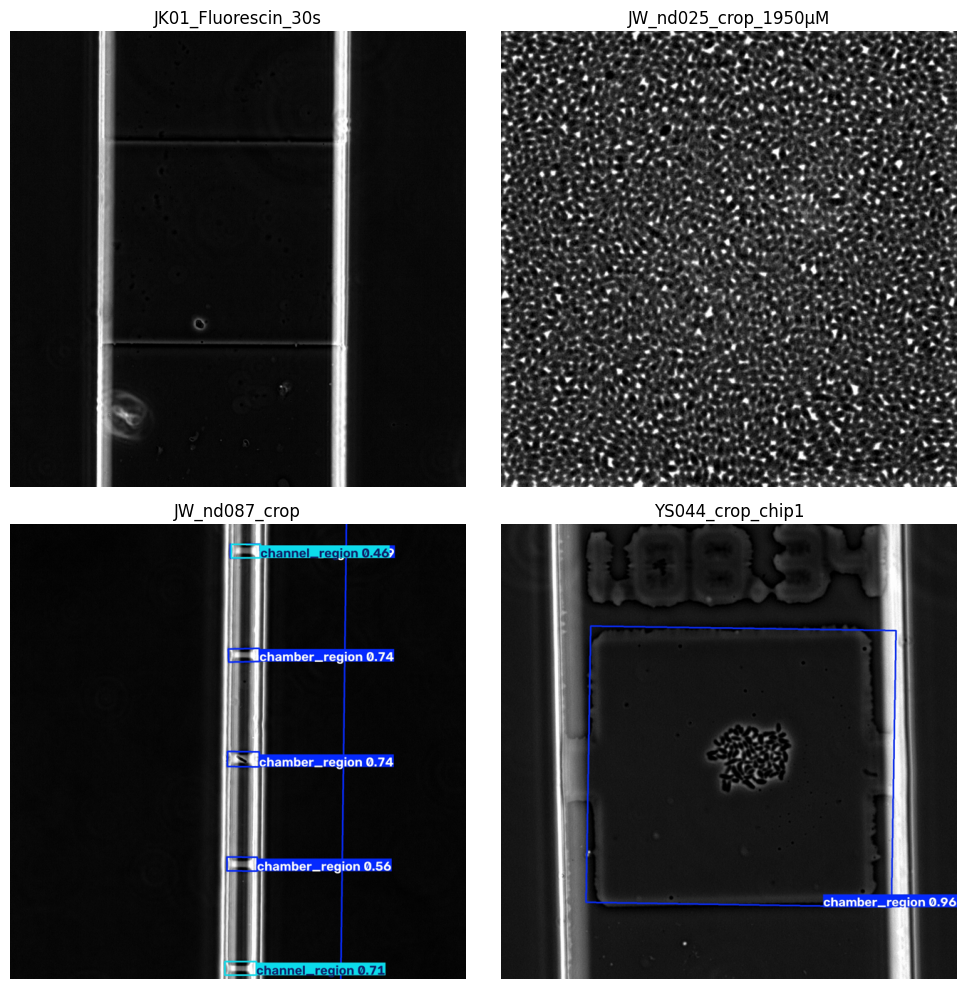

In [11]:
import matplotlib.pyplot as plt
from PIL import Image

img1 = Image.open("chip_images/Run 6/JK01_Fluorescin_30s_pos0_frame019.jpg")
img2 = Image.open("chip_images/Run 6/JW_nd025_crop_1950µM_pos4_frame088.jpg")
img3 = Image.open("chip_images/Run 6/JW_nd087_crop_pos0_frame118.jpg")
img4 = Image.open("chip_images/Run 6/YS044_crop_chip1_pos1_frame067.jpg")

img_resized1 = img1.resize((640, 640))
img_resized2 = img2.resize((640, 640))
img_resized3 = img3.resize((640, 640))
img_resized4 = img4.resize((640, 640))

bilder = [img_resized1, img_resized2, img_resized3, img_resized4]
titel = ["JK01_Fluorescin_30s", "JW_nd025_crop_1950µM", "JW_nd087_crop", "YS044_crop_chip1"]

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for ax, img, t in zip(axes.flat, bilder, titel):
    ax.imshow(img, cmap="gray")
    ax.set_title(t)
    ax.axis("off")

plt.tight_layout()
plt.show()